In this file, we will train a Support Vector Machine (SVM) on the train dataset (which contains no anomalies) as a one-classification. This will give us the boundary of what is normal and anything that is outside this boundary will be labelled as an anomaly. We will work with the P1 dataset.

In [2]:
import numpy as np
import pandas as pd
train = pd.DataFrame(np.load("../data/data/train/P-1.npy"))
test = pd.DataFrame(np.load("../data/data/test/P-1.npy"))
train

,0,1,2,3,4,5,6,7,8,9,...,15,16,17,18,19,20,21,22,23,24
0,-0.523155,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,-0.688857,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,-0.554993,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,-0.531114,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,-0.589001,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2867,-0.691751,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2868,-0.704052,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2869,-0.725760,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2870,-0.689580,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


Now it is important to note that SVM is for independent rows. Our data is time series where the rows are actually dependent on the rows around it. So we need to perform some feature engineering to get sliding windows to obtain some independence.

First we will eliminate collinearity in our columns.

In [3]:
#Let us store all the one hot encoded feature column names in a list
OHF = range(1,25)
crelation_matrix = train[OHF].corr().abs()
crelation_matrix

,1,2,3,4,5,6,7,8,9,10,...,15,16,17,18,19,20,21,22,23,24
1,1.000000,0.410546,0.842315,NaN,0.408575,0.023101,0.007019,NaN,0.140448,NaN,...,NaN,NaN,0.008506,0.008158,0.615935,NaN,0.160283,0.135184,NaN,NaN
2,0.410546,1.000000,0.013062,NaN,0.166085,0.192309,0.002882,NaN,0.002037,NaN,...,NaN,NaN,0.042106,0.042528,0.009171,NaN,0.383060,0.392263,NaN,NaN
3,0.842315,0.013062,1.000000,NaN,0.385865,0.063367,0.006322,NaN,0.075741,NaN,...,NaN,NaN,0.028653,0.028469,0.702095,NaN,0.023169,0.033299,NaN,NaN
4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,0.408575,0.166085,0.385865,NaN,1.000000,0.866187,0.016140,NaN,0.024837,NaN,...,NaN,NaN,0.316140,0.313152,0.274993,NaN,0.382151,0.384500,NaN,NaN
6,0.023101,0.192309,0.063367,NaN,0.866187,1.000000,0.013980,NaN,0.009882,NaN,...,NaN,NaN,0.368406,0.364977,0.044489,NaN,0.428563,0.441507,NaN,NaN
7,0.007019,0.002882,0.006322,NaN,0.016140,0.013980,1.000000,NaN,0.000986,NaN,...,NaN,NaN,0.006322,0.006281,0.004438,NaN,0.007523,0.007347,NaN,NaN
8,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,0.140448,0.002037,0.075741,NaN,0.024837,0.009882,0.000986,NaN,1.000000,NaN,...,NaN,NaN,0.004468,0.004440,0.003137,NaN,0.131045,0.005193,NaN,NaN
10,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [4]:
threshold = 0.95
const_cols = crelation_matrix.columns[crelation_matrix.isna().all()].tolist()

upper = crelation_matrix.where(np.triu(np.ones(crelation_matrix.shape, dtype=bool), k=1))
corr_cols = [col for col in upper.columns if (upper[col] > threshold).any()]

to_drop = const_cols + corr_cols

train = train.drop(columns = to_drop)
test = test.drop(columns = to_drop)
train

,0,1,2,3,5,6,7,9,11,13,17,19,21
0,-0.523155,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,-0.688857,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,-0.554993,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,-0.531114,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,-0.589001,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
2867,-0.691751,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2868,-0.704052,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2869,-0.725760,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2870,-0.689580,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [5]:
train.columns

Index([0, 1, 2, 3, 5, 6, 7, 9, 11, 13, 17, 19, 21], dtype='int64')

Now, let us perform feature engineering. Let us write a function that will take in a dataframe and output a dataframe of the engineered features for a rolling window of size wind.

In [6]:
def feature_engineering(df , wind):
    features = pd.DataFrame()
    features["value"] = df[0]
    features["rmean"] = df[0].rolling(window=wind).mean()
    features["diff"] = df[0].diff()
    features["diff_std"] = df[0].diff().rolling(window=wind).std()
    features["rmin"]= df[0].rolling(window=wind).min()
    features["rmax"]= df[0].rolling(window=wind).max()
    features["rstd"]= df[0].rolling(window=wind).std()
    for i in df.columns:
        features[f"feature {i}"] = df[i].rolling(window=wind).sum()
        
    return features.iloc[wind:]

window=50
train_features = feature_engineering(train,window)
train_features

,value,rmean,diff,diff_std,rmin,rmax,rstd,feature 0,feature 1,feature 2,feature 3,feature 5,feature 6,feature 7,feature 9,feature 11,feature 13,feature 17,feature 19,feature 21
50,-0.771346,-0.407815,0.002171,0.237831,-0.956585,0.753256,0.422444,-20.390737,4.0,2.0,2.0,12.0,9.0,0.0,0.0,0.0,0.0,2.0,1.0,4.0
51,-0.791606,-0.409870,-0.020260,0.236712,-0.956585,0.753256,0.424085,-20.493487,4.0,2.0,2.0,12.0,9.0,0.0,0.0,0.0,0.0,2.0,1.0,4.0
52,-0.752533,-0.413821,0.039074,0.235979,-0.956585,0.753256,0.426379,-20.691026,4.0,2.0,2.0,12.0,9.0,0.0,0.0,0.0,0.0,2.0,1.0,4.0
53,-0.777858,-0.418755,-0.025326,0.235963,-0.956585,0.753256,0.429183,-20.937770,4.0,2.0,2.0,12.0,9.0,0.0,0.0,0.0,0.0,2.0,1.0,4.0
54,-0.761939,-0.422214,0.015919,0.235856,-0.956585,0.753256,0.431275,-21.110708,4.0,2.0,2.0,12.0,9.0,0.0,0.0,0.0,0.0,2.0,1.0,4.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2867,-0.691751,-0.327467,-0.518090,0.220147,-0.937771,0.570188,0.419644,-16.373371,2.0,0.0,2.0,8.0,6.0,0.0,0.0,0.0,0.0,2.0,1.0,3.0
2868,-0.704052,-0.326353,-0.012301,0.220123,-0.937771,0.570188,0.418545,-16.317655,2.0,0.0,2.0,8.0,6.0,0.0,0.0,0.0,0.0,2.0,1.0,3.0
2869,-0.725760,-0.326252,-0.021708,0.220109,-0.937771,0.570188,0.418446,-16.312590,2.0,0.0,2.0,8.0,6.0,0.0,0.0,0.0,0.0,2.0,1.0,3.0
2870,-0.689580,-0.325051,0.036179,0.220150,-0.937771,0.570188,0.417290,-16.252532,2.0,0.0,2.0,8.0,6.0,0.0,0.0,0.0,0.0,2.0,1.0,3.0


In [7]:
from sklearn.svm import OneClassSVM
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import TimeSeriesSplit

In [8]:
model = Pipeline(steps=[
                        ("Scaler", StandardScaler()),
                        ("SVM" , OneClassSVM(nu=0.01))
                        ])

In [9]:
for w in [5,10,15,20]:
    train_features = feature_engineering(train,w)
    tscv = TimeSeriesSplit(n_splits=15, gap=w)
    gamma = [0.1 , 0.01, 0.001]
    results = pd.DataFrame(columns=gamma, index=range(15))
    results.index.name = "Split"

    for g in gamma:
        model.set_params(SVM__gamma=g)
        for i, (train_index, test_index) in enumerate(tscv.split(train_features)):
            X_train = train_features.iloc[train_index]
            X_test = train_features.iloc[test_index]
            model.fit(X_train)
            fpr = (model.predict(X_test)==-1).mean()
            results.loc[i,g]=fpr
    print(f"results for window length {w}")
    print(results)

results for window length 5
          0.100     0.010     0.001
Split                              
0      0.402235  0.100559  0.061453
1       0.22905  0.022346  0.011173
2      0.173184   0.03352  0.039106
3      0.167598  0.022346  0.022346
4      0.128492  0.022346  0.022346
5      0.083799  0.005587       0.0
6      0.111732  0.005587       0.0
7      0.128492   0.01676       0.0
8      0.067039  0.011173       0.0
9      0.094972  0.050279  0.072626
10     0.050279       0.0       0.0
11     0.027933  0.005587       0.0
12     0.139665  0.078212  0.005587
13     0.106145  0.044693  0.044693
14     0.089385   0.03352  0.027933
results for window length 10
          0.100     0.010     0.001
Split                              
0       0.44382  0.078652  0.033708
1      0.224719  0.073034  0.011236
2      0.219101  0.050562  0.044944
3      0.151685  0.011236  0.005618
4      0.219101  0.044944  0.033708
5      0.095506       0.0       0.0
6      0.123596  0.011236       0.0
7      

Let us try to perform the analysis only for telemetary.

In [10]:
for w in [5,10,15,20]:
    train_features = feature_engineering(train,w)
    train_features = train_features.iloc[:,:7]
    tscv = TimeSeriesSplit(n_splits=15, gap=w)
    gamma = [0.1 , 0.01, 0.001]
    results = pd.DataFrame(columns=gamma, index=range(15))
    results.index.name = "Split"

    for g in gamma:
        model.set_params(SVM__gamma=g)
        for i, (train_index, test_index) in enumerate(tscv.split(train_features)):
            X_train = train_features.iloc[train_index]
            X_test = train_features.iloc[test_index]
            model.fit(X_train)
            fpr = (model.predict(X_test)==-1).mean()
            results.loc[i,g]=fpr
    print(f"results for window length {w}")
    print(results)

results for window length 5
          0.100     0.010     0.001
Split                              
0      0.156425  0.044693  0.039106
1      0.078212  0.011173  0.011173
2      0.078212  0.039106   0.03352
3       0.03352       0.0       0.0
4      0.150838  0.005587  0.005587
5           0.0       0.0       0.0
6           0.0  0.005587  0.005587
7      0.039106  0.005587  0.005587
8      0.027933  0.011173   0.01676
9       0.03352   0.01676  0.005587
10     0.011173  0.011173  0.011173
11     0.022346       0.0       0.0
12     0.072626  0.094972  0.094972
13     0.055866  0.039106  0.039106
14      0.01676  0.022346  0.022346
results for window length 10
          0.100     0.010     0.001
Split                              
0      0.191011  0.016854  0.011236
1      0.078652  0.016854  0.016854
2      0.162921  0.061798  0.061798
3      0.033708       0.0       0.0
4      0.157303  0.011236  0.005618
5           0.0       0.0       0.0
6      0.005618  0.011236  0.011236
7      

Now let us test it on the test set and see how our model did.

### Choosing the final settings

Before touching the test set, we pick one configuration using only the training-set validation results above. For every window length, feature set (all features vs. telemetry only) and gamma, we compute the mean validation false-positive rate across the 15 splits. We take the configuration with the lowest mean FPR; ties go to the smaller window.

The test set and its labels are not used for this choice.

In [11]:
cv_rows = []
for w in [5, 10, 15, 20]:
    for telemetry_only in [False, True]:
        feats = feature_engineering(train, w)
        if telemetry_only:
            feats = feats.iloc[:, :7]
        tscv = TimeSeriesSplit(n_splits=15, gap=w)
        for g in [0.1, 0.01, 0.001]:
            model.set_params(SVM__gamma=g)
            fprs = []
            for train_index, val_index in tscv.split(feats):
                model.fit(feats.iloc[train_index])
                fprs.append((model.predict(feats.iloc[val_index]) == -1).mean())
            cv_rows.append({"window": w, "telemetry_only": telemetry_only,
                            "gamma": g, "mean_val_FPR": np.mean(fprs)})

cv_summary = (pd.DataFrame(cv_rows)
              .sort_values(["mean_val_FPR", "window"])
              .reset_index(drop=True))
display(cv_summary.head(10))

best = cv_summary.iloc[0]
best_window = int(best["window"])
best_gamma = float(best["gamma"])
telemetry_only = bool(best["telemetry_only"])
print(f"Selected: window={best_window}, gamma={best_gamma}, telemetry_only={telemetry_only}")

,window,telemetry_only,gamma,mean_val_FPR
0,10,True,0.001,0.017978
1,10,True,0.010,0.019101
2,5,True,0.001,0.019367
3,10,False,0.001,0.019850
4,5,False,0.001,0.020484
5,5,True,0.010,0.020484
6,15,True,0.001,0.026592
7,15,True,0.010,0.029588
8,5,False,0.010,0.030168
9,20,True,0.001,0.032959


Selected: window=10, gamma=0.001, telemetry_only=True


### Fit on the full training set and predict on the test set

We refit the selected configuration on all training rows. Then we build the test features with the same window and columns, and predict each test row (-1 = anomaly).

The true label of a test row is 1 if its index falls inside one of the expert-labelled anomaly intervals in `labeled_anomalies.csv` (inclusive endpoints), and 0 otherwise.

In [12]:
import ast

labels = pd.read_csv("../data/data/labeled_anomalies.csv")
labeled_intervals = ast.literal_eval(
    labels.loc[labels["chan_id"] == "P-1", "anomaly_sequences"].iloc[0])
print("Labelled anomaly intervals:", sorted(labeled_intervals))

train_feats = feature_engineering(train, best_window)
test_feats = feature_engineering(test, best_window)
if telemetry_only:
    train_feats = train_feats.iloc[:, :7]
    test_feats = test_feats.iloc[:, :7]

model.set_params(SVM__gamma=best_gamma)
model.fit(train_feats)

# 1 = predicted anomaly, 0 = predicted normal
y_pred = (model.predict(test_feats) == -1).astype(int)

# True point labels, aligned with the test feature rows (which keep their original index)
y_true = np.zeros(len(test), dtype=int)
for start, end in labeled_intervals:
    y_true[start:end + 1] = 1
y_true = y_true[test_feats.index]

print("Test rows evaluated:", len(y_true))
print("True anomalous rows:", y_true.sum())
print("Predicted anomalous rows:", y_pred.sum())

Labelled anomaly intervals: [[2149, 2349], [3539, 3779], [4536, 4844]]
Test rows evaluated: 8495
True anomalous rows: 751
Predicted anomalous rows: 301


### Point-level metrics

Each test row counts as one prediction:

- **Precision** = TP / (TP + FP): of the rows we flagged, how many were really anomalous.
- **Recall** = TP / (TP + FN): of the truly anomalous rows, how many we flagged.
- **False positive rate** = FP / (FP + TN): of the normal rows, how many we wrongly flagged.
- **F1** = the harmonic mean of precision and recall.

In [13]:
from sklearn.metrics import confusion_matrix, precision_score, recall_score, f1_score

tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()

point_metrics = pd.Series({
    "TP": tp, "FP": fp, "FN": fn, "TN": tn,
    "precision": precision_score(y_true, y_pred, zero_division=0),
    "recall": recall_score(y_true, y_pred, zero_division=0),
    "false positive rate": fp / (fp + tn),
    "F1": f1_score(y_true, y_pred, zero_division=0),
}, name="point-level", dtype=object)
point_metrics.to_frame()

,point-level
TP,193
FP,108
FN,558
TN,7636
precision,0.641196
recall,0.256991
false positive rate,0.013946
F1,0.36692


### Event-level metrics

Point-level recall is low whenever the model flags only part of a long anomaly. The original paper instead scores **events**: a labelled interval counts as detected if at least one alert overlaps it, and an alert that overlaps no labelled interval is a false positive. This uses `evaluate_event_detection()` from `detection.py`, the same scoring as the other notebooks.

Flagged rows are grouped into alert intervals. Flags separated by no more than `best_window` steps are merged into one alert, because every feature row summarises the previous `best_window` readings. Event-level FPR is not defined, since there are no "true negative events".

In [14]:
import sys
sys.path.insert(0, "..")
from detection import evaluate_event_detection

def flags_to_intervals(indices, max_gap=1):
    # Group sorted indices into inclusive (start, end) intervals
    if len(indices) == 0:
        return []
    indices = np.sort(np.asarray(indices))
    breaks = np.where(np.diff(indices) > max_gap)[0]
    starts = np.r_[indices[0], indices[breaks + 1]]
    ends = np.r_[indices[breaks], indices[-1]]
    return [(int(s), int(e)) for s, e in zip(starts, ends)]

flagged_indices = test_feats.index.to_numpy()[y_pred == 1]
alert_intervals = flags_to_intervals(flagged_indices, max_gap=best_window)
event_eval = evaluate_event_detection(alert_intervals, labeled_intervals)

print("Number of alert intervals:", len(alert_intervals))
for interval, detected in zip(labeled_intervals, event_eval["detected_event_mask"]):
    print(f"Labelled event {interval}: {'Detected' if detected else 'Missed'}")

event_metrics = pd.Series({
    "TP": event_eval["TP"], "FP": event_eval["FP"], "FN": event_eval["FN"],
    "precision": event_eval["precision"], "recall": event_eval["recall"],
    "F1": event_eval["f1"],
}, name="event-level", dtype=object)
event_metrics.to_frame()

Number of alert intervals: 48
Labelled event [2149, 2349]: Detected
Labelled event [4536, 4844]: Detected
Labelled event [3539, 3779]: Detected


,event-level
TP,3
FP,43
FN,0
precision,0.065217
recall,1.0
F1,0.122449


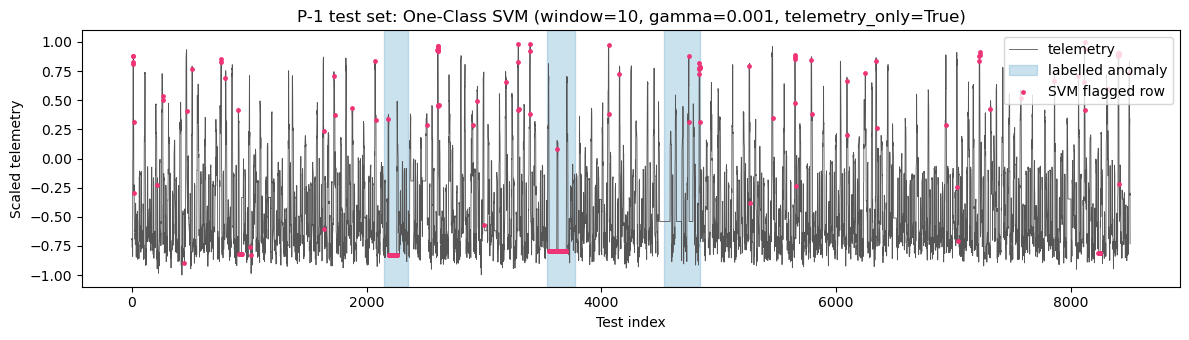

In [16]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(12, 3.5))
ax.plot(test.index, test[0], lw=0.6, color="#555555", label="telemetry")
for k, (s, e) in enumerate(labeled_intervals):
    ax.axvspan(s, e, color="#67a9cf", alpha=0.35, label="labelled anomaly" if k == 0 else None)
ax.scatter(flagged_indices, test.loc[flagged_indices, 0], s=6, color="#EE3377",
           label="SVM flagged row", zorder=3)
ax.set_title(f"P-1 test set: One-Class SVM (window={best_window}, gamma={best_gamma}, "
             f"telemetry_only={telemetry_only})")
ax.set_xlabel("Test index")
ax.set_ylabel("Scaled telemetry")
ax.legend(loc="upper right")
plt.tight_layout()
plt.show()